In [50]:
import pandas as pd
import os
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [ ]:
file_path = r"D:\Project_Github\set_fear_index\stock_name_dateset\parquet\ADVANC.BK.parquet"

df = pd.read_parquet(file_path)

display(df.head())

Price,Open,High,Low,Close,Volume
Date,,,,,
2016-11-11,96.220726,96.220726,95.258518,95.579254,9496400
2016-11-14,94.937805,95.258541,93.654861,93.654861,10092400
2016-11-15,93.975586,94.617058,93.654850,93.975586,6678100
2016-11-16,94.296317,94.617053,92.051167,92.371902,11704300
2016-11-17,92.371898,93.013370,92.051163,92.051163,6044800


In [48]:
df.index.min()

Timestamp('2016-11-11 00:00:00')

In [8]:
stock_name = []
word = ''
count = 0
for i in file_path:
    if i == '\\':
        count += 1
    if count == 5:
        word = word + i
        if i == '.':
            stock_name.append(word[1:]+'BK')
            break
print(stock_name)

['ADVANC.BK']


In [ ]:
folder_path = Path(r"D:\Project_Github\set_fear_index\stock_name_dateset\parquet")
stock_name = []
for file_path in folder_path.iterdir():
    stock_name.append(file_path.name.split(".p")[0])
print(stock_name)

['GULF.BK', 'SCGP.BK', 'RATCH.BK', 'TCAP.BK', 'STGT.BK', 'CPALL.BK', 'CK.BK', 'TOP.BK', 'TPIPL.BK', 'DELTA.BK', 'TASCO.BK', 'HMPRO.BK', 'TU.BK', 'EGCO.BK', 'TISCO.BK', 'TIDLOR.BK', 'MRDIYT.BK', 'OR.BK', 'CCET.BK', 'BJC.BK', 'VGI.BK', 'OSP.BK', 'BCP.BK', 'BANPU.BK', 'SAWAD.BK', 'COM7.BK', 'KBANK.BK', 'PSH.BK', 'BTS.BK', 'CBG.BK', 'KKP.BK', 'PTTGC.BK', 'KCE.BK', 'SPRC.BK', 'TFG.BK', 'JAS.BK', 'SCCC.BK', 'BA.BK', 'GLOBAL.BK', 'JMART.BK', 'CPN.BK', 'PTG.BK', 'CPF.BK', 'THAI.BK', 'SCB.BK', 'BAM.BK', 'BEC.BK', 'SCC.BK', 'BLA.BK', 'TPIPP.BK', 'JMT.BK', 'TLI.BK', 'M.BK', 'AWC.BK', 'IVL.BK', 'TOA.BK', 'PTTEP.BK', 'BH.BK', 'BBL.BK', 'BEAUTY.BK', 'GPSC.BK', 'PTT.BK', 'STA.BK', 'AOT.BK', 'BGRIM.BK', 'CENTEL.BK', 'KTB.BK', 'KTC.BK', 'IRPC.BK', 'BDMS.BK', 'BEM.BK', 'TTB.BK', 'ITD.BK', 'WHA.BK', 'EA.BK', 'TRUE.BK', 'LH.BK', 'MINT.BK', 'CRC.BK', 'MTC.BK', 'ITC.BK', 'TTW.BK', 'ADVANC.BK']


In [ ]:
folder_path = Path(r"D:\Project_Github\set_fear_index\stock_name_dateset\parquet")
stock_name_date = []
for file_path in folder_path.iterdir():
    df = pd.read_parquet(file_path)
    stock_name_date.append((file_path.name.split(".p")[0], df.index.min(), df.index.max()))

print(stock_name_date)


[('GULF.BK', Timestamp('2025-04-03 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('SCGP.BK', Timestamp('2020-10-22 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('RATCH.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('TCAP.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('STGT.BK', Timestamp('2020-07-02 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('CPALL.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('CK.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('TOP.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('TPIPL.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('DELTA.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('TASCO.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('HMPRO.BK', Timestamp('2016-11-11 00:00:00'), Timestamp('2026-11-11 00:00:00')), ('TU.BK', Timestamp('201

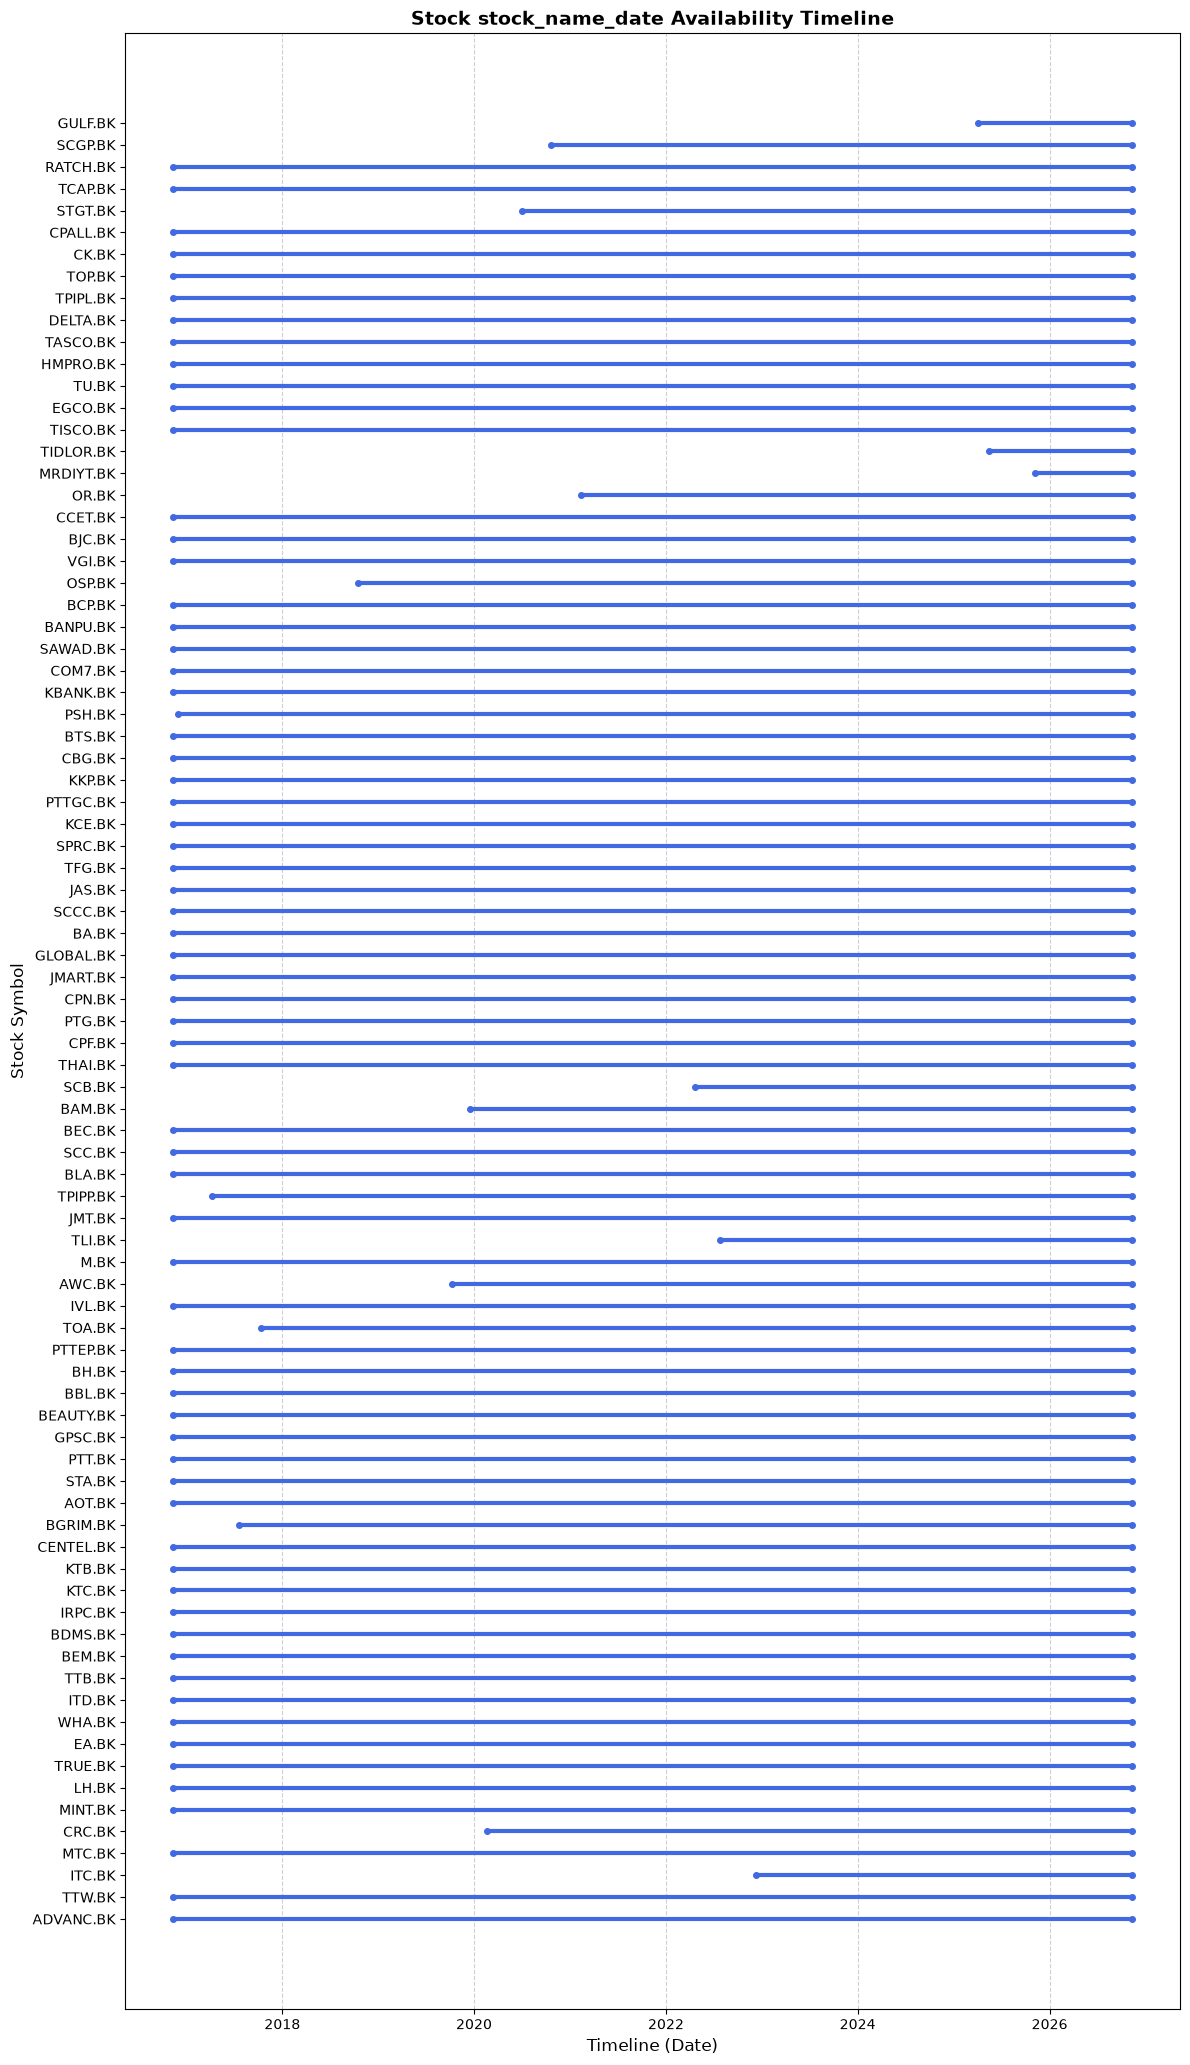

In [51]:
tickers = [item[0] for item in stock_name_date]
start_dates = [item[1] for item in stock_name_date]
end_dates = [item[2] for item in stock_name_date]

# กำหนดขนาดรูป (ความสูงปรับตามจำนวนหุ้นเพื่อให้สัดส่วนพอดี)
fig, ax = plt.subplots(figsize=(12, max(8, len(stock_name_date) * 0.25)))

# วาดเส้น Timeline ของแต่ละหุ้น
for i, (ticker, start, end) in enumerate(stock_name_date):
  ax.plot(
      [start, end],
      [i, i],
      marker="o",
      markersize=4,
      color="royalblue",
      linewidth=3,
      solid_capstyle="round",
  )

# ตั้งค่าแกน Y ให้แสดงชื่อหุ้น
ax.set_yticks(range(len(tickers)))
ax.set_yticklabels(tickers)

# สลับแกน Y ให้หุ้นตัวแรกอยู่ด้านบนสุด
ax.invert_yaxis()

# ตกแต่งกราฟ
ax.set_xlabel("Timeline (Date)", fontsize=12)
ax.set_ylabel("Stock Symbol", fontsize=12)
ax.set_title("Stock stock_name_date Availability Timeline", fontsize=14, fontweight="bold")

# เปิดเส้นตารางแนวตั้งเพื่อให้ดูวันที่ได้ง่ายขึ้น
ax.grid(True, axis="x", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

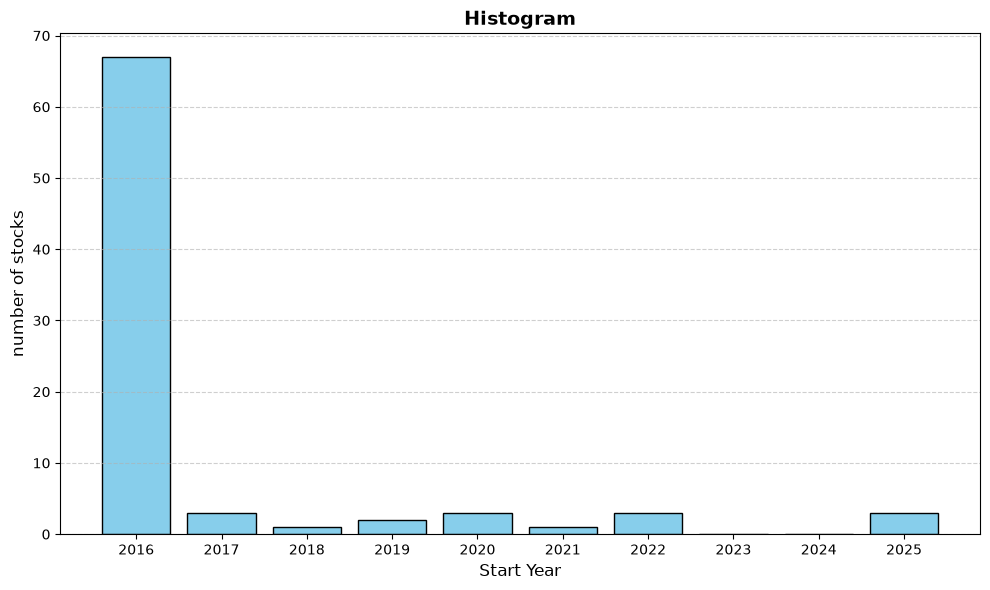

In [53]:
start_years = [item[1].year for item in stock_name_date]

plt.figure(figsize=(10, 6))

# bins กำหนดช่วงความกว้างของแท่งกราฟ (ครอบคลุมทุกปีตั้งแต่ปีแรกถึงปีปัจจุบัน)
bins = range(min(start_years), max(start_years) + 2)

plt.hist(
    start_years,
    bins=bins,
    color="skyblue",
    edgecolor="black",
    align="left",
    rwidth=0.8,
)

# 3. ตกแต่งกราฟ
plt.title(
    "Histogram",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Start Year", fontsize=12)
plt.ylabel("number of stocks", fontsize=12)

# แสดงตัวเลขปีที่แกน X ให้ครบทุกปี
plt.xticks(range(min(start_years), max(start_years) + 1))

# เปิดเส้นตารางแนวตั้ง
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()